# How the Grover winner detector works

**Part 1 of 3: How it works** · [Part 2: Noise →](02_noise.ipynb) ·
[Part 3: Hardware](03_hardware.ipynb) · [README](../README.md)

**Question.** Can a quantum search tell who won a game of tic-tac-toe, and can
the circuit be made small enough to survive on a real quantum computer?

**Result.** One step of Grover's search over the 8 winning lines points at the
winner: on a perfect simulator 78% of measurements land on a single winning
line, against 12.5% by chance. Rewriting the original circuit took it from 22
qubits to 12 and cut its two-qubit gates, where most hardware errors happen,
several-fold (chart below), which is what lets it run on IBM's devices.

In [1]:
import json
import math

import matplotlib.pyplot as plt
import numpy as np
from qiskit import ClassicalRegister, QuantumCircuit
from qiskit.circuit import QuantumRegister
from qiskit.quantum_info import Statevector

from qttt import plots
from qttt.backends import IdealBackend, get_backend
from qttt.board import EMPTY, O, X, classical_winning_lines
from qttt.detector import DEFAULT_BUDGET, DEFAULT_SHOTS, detect_winner
from qttt.encoding import encode_player_board
from qttt.grover import build_phase_kickback_circuit, build_search_circuit, diffuser
from qttt.noise import ideal_line_probabilities
from qttt.oracles import player_oracle
from qttt.stats import binomial_cutoff, binomial_pmf

SEED = 4903
_ = EMPTY
CASES = {  # X has just moved on all three
    "Single win": (X, O, X,
                   O, X, O,
                   _, _, X),
    "Double win": (X, X, X,
                   X, O, O,
                   X, O, O),
    "No win": (X, O, X,
               X, O, O,
               O, X, X),
}


def line_probabilities(qc):
    """Exact probability of each line index, read from the statevector (no sampling)."""
    qc = qc.remove_final_measurements(inplace=False)
    return Statevector(qc).probabilities([qc.find_bit(q).index for q in qc.qregs[1]])

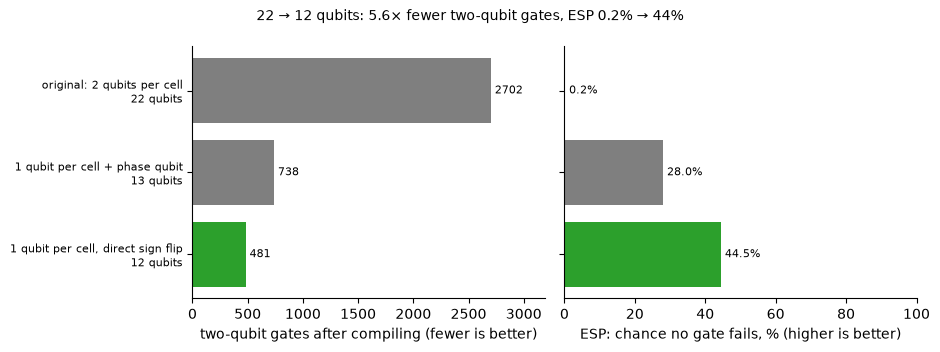

In [2]:
# The circuit's three versions, compiled for fake_kingston (a simulated copy of IBM's ibm_kingston), best of 5.
kingston = get_backend("fake_kingston", seed=SEED, transpile_seeds=5)
empty = [EMPTY] * 9
versions = {
    "original: 2 qubits per cell": build_search_circuit("full", empty),
    "1 qubit per cell + phase qubit": build_phase_kickback_circuit(empty, X),
    "1 qubit per cell, direct sign flip": build_search_circuit("player", empty, X),
}
compiled = {name: (qc, kingston.metrics(kingston.transpile(qc))) for name, qc in versions.items()}
rows = [(name, qc.num_qubits, m.two_qubit_gates, 10 ** m.log10_esp) for name, (qc, m) in compiled.items()]
(_, q0, g0, e0), (_, q1, g1, e1) = rows[0], rows[-1]
plots.circuit_versions(rows, f"{q0} → {q1} qubits: {g0 / g1:.1f}× fewer two-qubit gates, ESP {e0:.1%} → {e1:.0%}")
plt.show()

**What to notice:** ESP (*estimated success probability*) is the chance that
no gate in the compiled circuit fails, worked out from IBM's published error
rate for every gate. The original 22-qubit circuit has almost none; the 12-qubit version
keeps enough signal to work, as Part 2 shows. Section 9 explains each step.

## 1. What is being searched: 8 lines

Each winning line gets an index 0–7, stored in 3 qubits. Grover's search runs
over these 8 indices, not over the board. The same numbering is used in every
chart in Parts 1–3.

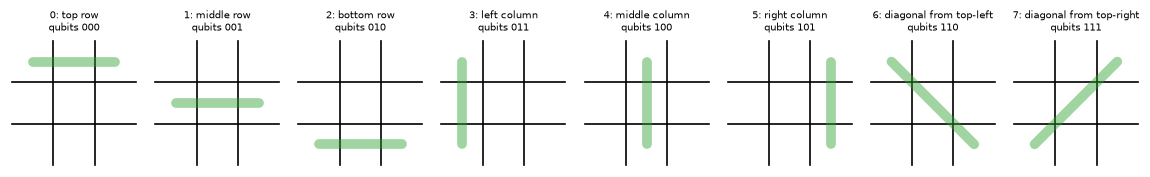

In [3]:
plots.line_key()
plt.show()

### When the check runs: turn 5 onward

A line needs three marks from the same player. X moves on turns 1, 3, 5, 7 and 9,
and O on turns 2, 4, 6 and 8, so the earliest anyone can complete a line is X's
third mark on turn 5. On turns 1–4 the answer is always "no winner", so the
game skips the check.

From turn 5 on, the check runs after every move and asks only about the player
who just moved: if the other player had a line, an earlier check would already
have ended the game. Two lines at once can only come from one move that
finishes both, which happens only on X's fifth mark on turn 9: the double win.

Of the 5,478 positions reachable in a real game, the 4,388 from turn 5 on are
the ones the detector ever sees: 3,446 with no winner, 920 with one winning
line and 22 with two. The three boards used throughout these notebooks, one of
each kind:

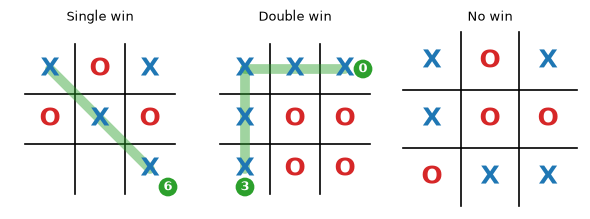

In [4]:
plots.show_boards({name: (board, classical_winning_lines(board, X)) for name, board in CASES.items()})
plt.show()

## 2. Loading the board: 12 qubits

Only the player who just moved can have a line, and the game knows who that
is classically. So each cell needs one qubit: |1⟩ if that player owns it, |0⟩ otherwise
(empty or the opponent's). With the 3 line-index qubits that is 12 qubits.
(The original circuit used 2 qubits per cell to tell X and O apart, plus a helper
qubit: 22 qubits. Section 9 compares the versions.)

Example: on the single-win board X has just moved and owns cells 0, 2, 4 and
8, so an X gate sets those 4 qubits to |1⟩:

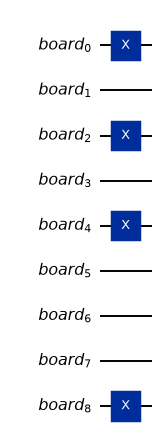

In [5]:
board = CASES["Single win"]
board_reg = QuantumRegister(9, "board")
encoder = QuantumCircuit(board_reg)
encode_player_board(encoder, board_reg, board, X)
encoder.draw("mpl", scale=0.7)

## 3. The oracle: flip the sign of winning lines

The *oracle* is the part of a Grover search that recognises an answer. Here it
gives every line index the player owns a minus sign and changes nothing else.

For each line i, the oracle temporarily flips the line-index qubits so that index i
reads as 111, then applies one *multi-controlled Z* (MCZ) gate on 6 qubits: the
3 line-index qubits and the line's 3 cell qubits. An MCZ flips the sign of the
state when all 6 qubits are 1 and does nothing otherwise. 8 lines, 8 MCZ gates.

Devices have no MCZ gate, so each one is built from a *multi-controlled X*
(MCX, a NOT that fires only when all its control qubits are 1): 5 of the
qubits are controls and the 6th, the line's last cell, is the target between
two H gates (H · X · H = Z). That is the H–MCX–H pattern in the drawing.

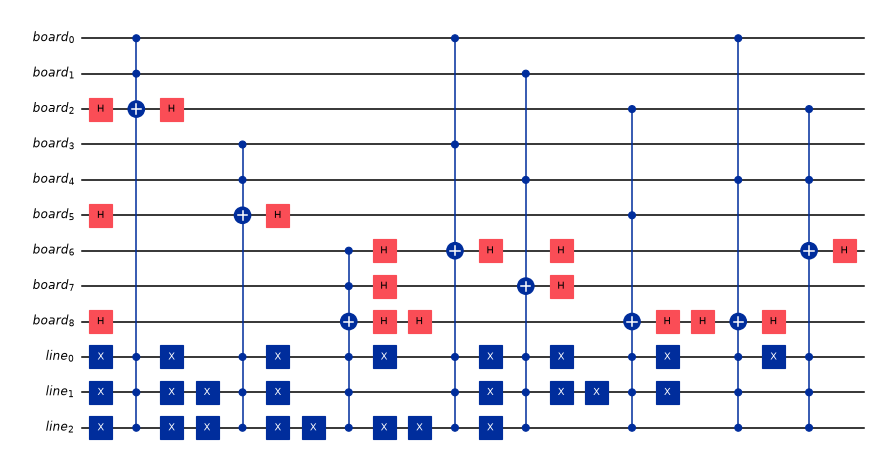

In [6]:
line_reg = QuantumRegister(3, "line")
oracle = QuantumCircuit(board_reg, line_reg)
player_oracle(oracle, board_reg, line_reg)
oracle.draw("mpl", fold=40, scale=0.55)

Checking the effect: start from all 8 indices with equal amplitude, apply the
oracle, and read the sign of each index's amplitude.

In [7]:
qc = QuantumCircuit(board_reg, line_reg)
encode_player_board(qc, board_reg, board, X)
qc.h(line_reg)
qc.compose(oracle, inplace=True)
state = Statevector(qc)
owned = sum(1 << c for c in range(9) if board[c] == X)  # the board qubits' fixed basis state
signs = [int(np.sign(state.data[owned | (i << 9)].real)) for i in range(8)]
print("winning lines:", sorted(classical_winning_lines(board, X)))
print("sign of each line index after the oracle:", signs)

winning lines: [6]
sign of each line index after the oracle: [1, 1, 1, 1, 1, 1, -1, 1]


## 4. The diffuser: turn the sign into probability

A sign alone does not change what is measured. The *diffuser* reflects every
amplitude about the mean, which boosts the index with the flipped sign and
shrinks the rest.

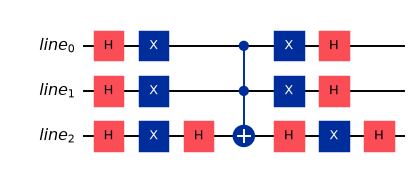

In [8]:
d = QuantumCircuit(line_reg)
diffuser(d, line_reg)
d.draw("mpl", scale=0.7)

In numbers, for the single-win board (winning line 6): all 8 indices start at
1/√8 ≈ 0.354. The oracle flips line 6 to −0.354, which pulls the mean down to
0.265. Reflecting about the mean (new = 2 · mean − old) sends line 6 to 0.884
and every other line to 0.177. Squared: 78% on the winner, 3% on each of the
others.

<details><summary>A note on the sign</summary>

The circuit's diffuser also multiplies the whole state by −1. That is a global
phase, which changes nothing that can be measured, so the chart leaves it out.
</details>

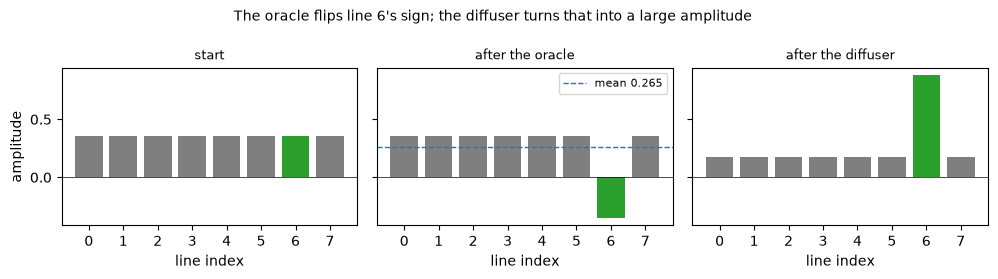

In [9]:
def line_amplitudes(qc):
    """Amplitude of each line index with this board loaded (the board qubits are in a fixed state)."""
    data = Statevector(qc).data
    return np.array([data[owned | (i << 9)].real for i in range(8)])


stages = QuantumCircuit(board_reg, line_reg)
encode_player_board(stages, board_reg, board, X)
stages.h(line_reg)
start = line_amplitudes(stages)
stages.compose(oracle, inplace=True)
flipped = line_amplitudes(stages)
diffuser(stages, line_reg)
after = -line_amplitudes(stages)  # undo the diffuser's global phase of -1

plots.probability_bars({"start": (start, [6]), "after the oracle": (flipped, [6]), "after the diffuser": (after, [6])},
                       ylabel="amplitude", mean=(1, flipped.mean()),
                       title="The oracle flips line 6's sign; the diffuser turns that into a large amplitude")
plt.show()

## 5. The whole circuit

Load the board, put the line register in an equal superposition, one oracle,
one diffuser, measure the 3 line qubits.

12 qubits, 8 MCX gates (one per MCZ)


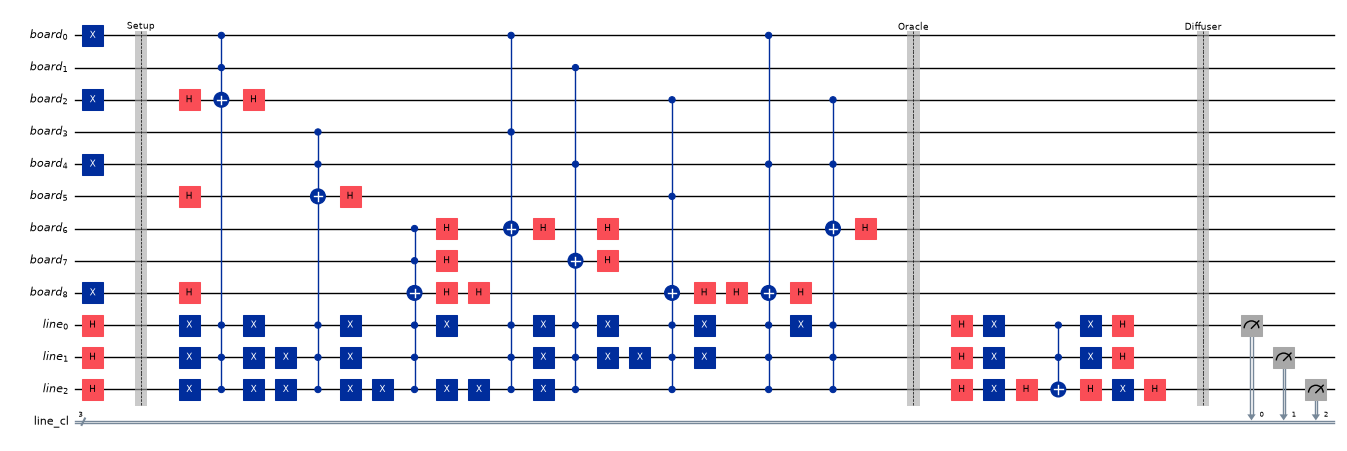

In [10]:
circuit = build_search_circuit("player", board, X)
print(f"{circuit.num_qubits} qubits, {circuit.count_ops().get('mcx', 0)} MCX gates (one per MCZ)")
circuit.draw("mpl", fold=45, scale=0.5)

## 6. Why exactly one Grover iteration

One *iteration* is one oracle plus one diffuser. With M of the 8 lines marked
and sin θ = √(M/8), k iterations put sin²((2k+1)θ) of the probability on the
marked lines. A legal board has M = 0, 1 or 2.

| iterations | M = 1 (on the winner) | M = 2 (on each winner) |
| ---: | ---: | ---: |
| 0 | 12.5% | 12.5% |
| 1 | 78.1% | 50.0% |
| 2 | 94.5% | 12.5% |
| 3 | 33.0% | 12.5% |

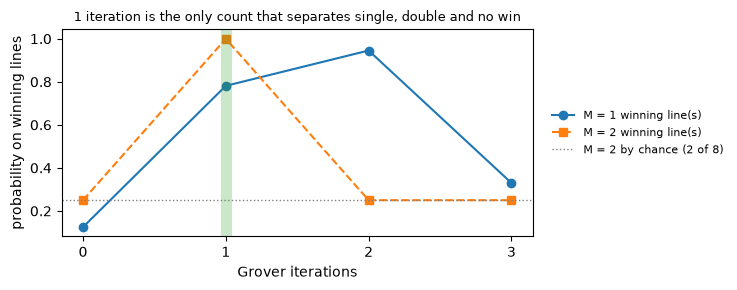

In [11]:
def on_each_winner(m, k):
    return math.sin((2 * k + 1) * math.asin(math.sqrt(m / 8))) ** 2 / m


display(plots.table(["iterations", "M = 1 (on the winner)", "M = 2 (on each winner)"],
                    [(k, f"{on_each_winner(1, k):.1%}", f"{on_each_winner(2, k):.1%}") for k in range(4)], "rrr"))
plots.grover_iterations()
plt.show()

The reason is easiest to see as a rotation. Split the state into its part on
the winning lines (|good⟩) and the rest (|bad⟩): it is a unit vector in that
plane, starting at angle θ from |bad⟩. Each iteration rotates it by 2θ toward
|good⟩, and the chance of measuring a winner is sin² of the angle.

- M = 1: θ ≈ 20.7°, so one iteration reaches 62° (78%); a second reaches 104°,
  just past |good⟩ (94.5%).
- M = 2: θ = 30°, so one iteration lands exactly on |good⟩ (100%); a second
  overshoots to 150°, back to the starting 25%.
- M = 0: θ = 0; nothing is marked, so nothing rotates.

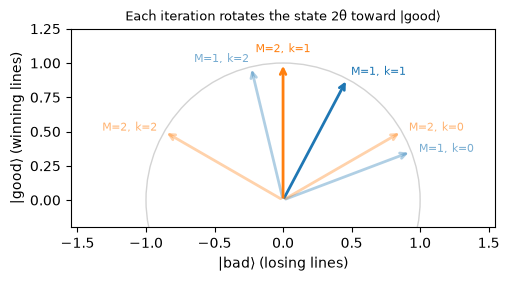

In [12]:
plots.grover_rotation()
plt.show()

One iteration separates every case: 78% on a single winner, 50/50 on a
double win, flat 12.5% with no winner. Two iterations push a single winner to
94.5% but send a double win right back to 12.5% everywhere, indistinguishable
from no winner. **The original circuit used 2 iterations, which makes double
wins undetectable.** Reproducing that with the same oracle and diffuser:

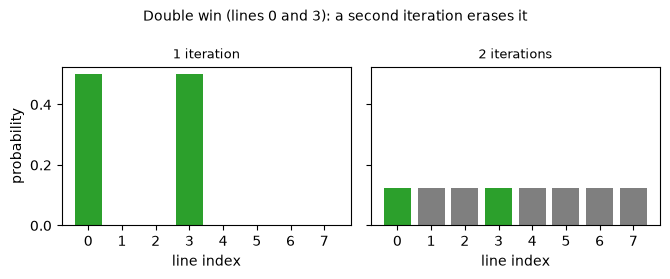

In [13]:
def search(board, player, iterations):
    board_reg = QuantumRegister(9, "board")
    line_reg = QuantumRegister(3, "line")
    qc = QuantumCircuit(board_reg, line_reg, ClassicalRegister(3, "line_cl"))
    encode_player_board(qc, board_reg, board, player)
    qc.h(line_reg)
    for _ in range(iterations):
        player_oracle(qc, board_reg, line_reg)
        diffuser(qc, line_reg)
    return qc


double = CASES["Double win"]
plots.probability_bars({f"{k} iteration{'s' if k > 1 else ''}": (line_probabilities(search(double, X, k)), [0, 3])
                        for k in (1, 2)},
                       title="Double win (lines 0 and 3): a second iteration erases it")
plt.show()

## 7. The three boards on a perfect simulator

Exact probabilities from the statevector; the cell also checks each against
the formula above.

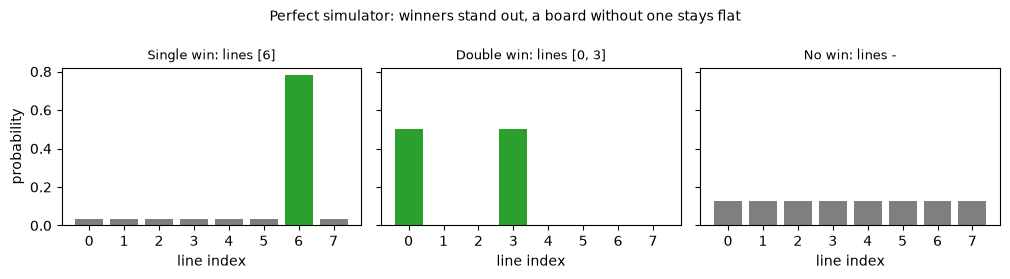

In [14]:
panels = {}
for name, board in CASES.items():
    winners = classical_winning_lines(board, X)
    probs = line_probabilities(build_search_circuit("player", board, X))
    assert np.allclose(probs, ideal_line_probabilities(winners))
    panels[f"{name}: lines {sorted(winners) or '-'}"] = (probs, winners)
plots.probability_bars(panels, title="Perfect simulator: winners stand out, a board without one stays flat")
plt.show()

## 8. From counts to a verdict

A real run gives counts, not probabilities: 1024 *shots* (repeated runs of the
circuit), each landing on one line index. A line is *flagged* when its count
reaches a cutoff, and each flagged line is checked on the board (3 cell
lookups). A confirmed line is always a real win, so noise can make the
detector miss a win but never invent one.

The cutoff is set by a **check budget**: on a board with no winner each line
gets 1/8 of the shots on average, and the cutoff is the lowest count at which
the expected number of falsely flagged lines per board is at most 0.2, that
is one wasted classical check every five boards.

At 1024 shots and a budget of 0.2 the cutoff is **150** counts (14.6% of shots).

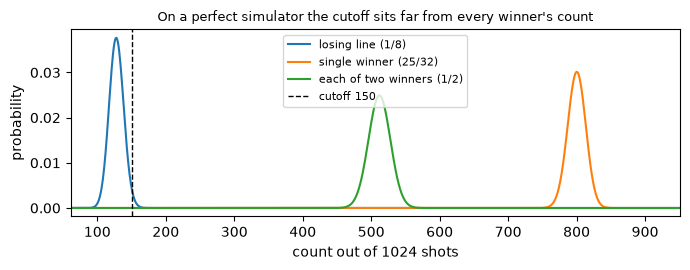

| board | counts per line index | flagged | confirmed | rejected | winner | classical checks |
| :--- | :--- | :--- | :--- | :--- | :--- | :--- |
| Single win | (44, 40, 27, 31, 33, 31, 787, 31) | [6] | [6] | [] | X | 1 |
| Double win | (531, 0, 0, 493, 0, 0, 0, 0) | [0, 3] | [0, 3] | [] | X | 2 |
| No win | (142, 125, 138, 126, 121, 129, 131, 112) | [] | [] | [] | none | 0 |

In [15]:
shots = DEFAULT_SHOTS
cutoff = binomial_cutoff(shots, DEFAULT_BUDGET)
display(plots.markdown(f"At {shots} shots and a budget of {DEFAULT_BUDGET} the cutoff is **{cutoff}** counts "
                       f"({cutoff / shots:.1%} of shots)."))
plots.count_distributions(shots, cutoff, binomial_pmf)
plt.show()

rows, runs = [], {}
for name, board in CASES.items():
    r = runs[name] = detect_winner(board, player=X, shots=shots, backend=IdealBackend(seed=SEED))
    rows.append((name, r.run.counts, list(r.candidates), sorted(r.lines), list(r.rejected), r.winner or "none",
                 r.checks))
plots.table(["board", "counts per line index", "flagged", "confirmed", "rejected", "winner", "classical checks"],
            rows, "lllllll")

The same three runs drawn on their boards: each of the 8 lines is drawn
through its cells, as thick as its share of the shots, with its index and
share written where it leaves the board (bold once it reaches the cutoff).

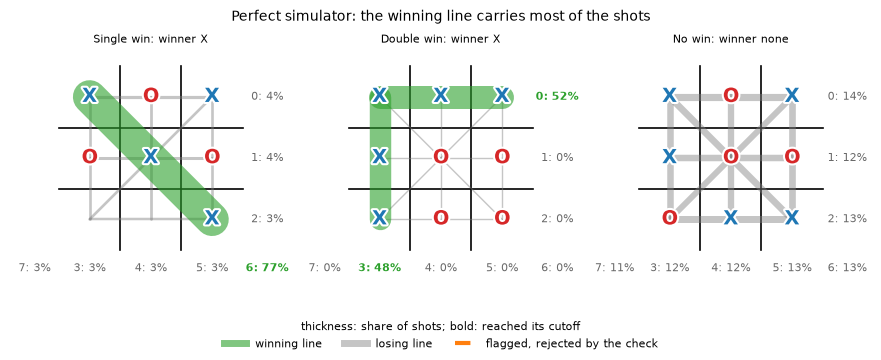

In [16]:
plots.board_results([(board, runs[name].run.counts, (cutoff,) * 8, classical_winning_lines(board, X),
                      runs[name].rejected, f"{name}: winner {runs[name].winner or 'none'}")
                     for name, board in CASES.items()],
                    "Perfect simulator: the winning line carries most of the shots", cols=3)
plt.show()

## 9. From 22 qubits to 12

The oracle is the expensive part. No current device runs a 6-qubit gate
directly, so the compiler rewrites every MCX into one- and two-qubit gates. On
some devices, such as IBM's and Google's superconducting chips, each qubit is
coupled only to its neighbours, so the compiler also adds swaps to bring the
qubits of each gate together. Other devices, such as trapped-ion and
neutral-atom machines, avoid most of these swaps by coupling any pair of
qubits or by moving the qubits themselves. On most current hardware,
two-qubit gates are where most errors happen.

The chart at the top showed the three versions:

- **Original, 22 qubits:** 2 qubits per cell so X and O can both be
  checked, and the sign flip made by *phase kickback*: an MCX (9 controls)
  whose target is an extra "phase" qubit prepared in |−⟩. Flipping |−⟩ only
  multiplies it by −1, so the minus sign lands on the line index instead.
- **One qubit per cell, 13 qubits:** only the player who just moved is
  checked, so each MCX needs 6 controls, still onto the phase qubit
  (`qttt.grover.build_phase_kickback_circuit`).
- **This version, 12 qubits:** the MCZ flips the sign directly, so the phase
  qubit is gone and each MCX has only 5 controls.

The 13-qubit and 12-qubit versions give exactly the same probabilities:

In [17]:
for name, board in CASES.items():
    same = np.allclose(line_probabilities(build_phase_kickback_circuit(board, X)),
                       line_probabilities(build_search_circuit("player", board, X)))
    print(f"{name:11} 13-qubit and 12-qubit probabilities equal: {same}")

Single win  13-qubit and 12-qubit probabilities equal: True
Double win  13-qubit and 12-qubit probabilities equal: True
No win      13-qubit and 12-qubit probabilities equal: True


One more option: a spare qubit that starts in |0⟩ (an *ancilla*) lets each
5-control MCX be built from fewer, shallower pieces ([Khattar & Gidney, *Quantum* 9, 1752, 2025](https://doi.org/10.22331/q-2025-05-21-1752)),
and is returned to |0⟩ afterwards. All four, compiled for `fake_kingston`
(5 *compiler seeds*, best kept: the compiler places and routes qubits with
some randomness, so it is run 5 times):

In [18]:
with_ancilla = build_search_circuit("player", empty, X, ancilla=True)
compiled["same + 1 ancilla qubit"] = (with_ancilla, kingston.metrics(kingston.transpile(with_ancilla)))


def score(m):
    return 10 ** (m.log10_esp + m.log10_idle + m.log10_readout)


plots.table(["version", "qubits", "two-qubit gates", "depth", "ESP", "idle", "readout", "score"],
            [(name, qc.num_qubits, m.two_qubit_gates, m.depth, f"{10 ** m.log10_esp:.1%}",
              f"{10 ** m.log10_idle:.1%}", f"{10 ** m.log10_readout:.1%}", f"{score(m):.1%}")
             for name, (qc, m) in compiled.items()], "lrrrrrrr")

| version | qubits | two-qubit gates | depth | ESP | idle | readout | score |
| :--- | ---: | ---: | ---: | ---: | ---: | ---: | ---: |
| original: 2 qubits per cell | 22 | 2702 | 6402 | 0.2% | 1.6% | 97.2% | 0.0% |
| 1 qubit per cell + phase qubit | 13 | 738 | 1772 | 28.0% | 41.3% | 95.8% | 11.1% |
| 1 qubit per cell, direct sign flip | 12 | 481 | 1588 | 44.5% | 55.8% | 95.8% | 23.8% |
| same + 1 ancilla qubit | 13 | 464 | 997 | 45.3% | 49.6% | 96.8% | 21.7% |

**Fewest gates is not always best.** ESP leaves out the time qubits spend
waiting, which on these devices costs about as much as the gates. So the
package scores each compiled circuit by three published numbers multiplied
together, and compiles the 12-qubit circuit with and without the ancilla and
keeps the higher score (`ancilla="auto"`, the default):

- **ESP:** chance no gate fails.
- **idle:** chance the line qubits (and the ancilla) keep their phase while
  they wait, from each qubit's measured T1 and T2 (how long it holds a 1, and
  holds a phase). The board qubits only hold 0 or 1, so their waiting does not
  count.
- **readout:** chance the 3 line qubits are read correctly.

In [19]:
plain, anc = compiled["1 qubit per cell, direct sign flip"][1], compiled["same + 1 ancilla qubit"][1]
pick = kingston.metrics(kingston.search_template("player"))
saved = json.loads(open("../results/noise_bias_score.json").read())
share = {run["ancilla"]: np.mean([r["counts"][r["winning_lines"][0]] / sum(r["counts"])
                                  for r in run["rows"] if r["case"].startswith("single")]) for run in saved}
plots.markdown(
    f"On this snapshot the plain circuit has {plain.two_qubit_gates} two-qubit gates against the ancilla "
    f"version's {anc.two_qubit_gates}, but scores {score(plain):.1%} against {score(anc):.1%}, so `auto` keeps "
    f"the circuit **{'with' if pick.ancilla else 'without'}** the ancilla. Simulated with full noise "
    f"(`scripts/noise_bias.py`, saved in `results/noise_bias_score.json`), a single winner keeps "
    f"{share[False]:.2f} of the shots without the ancilla and {share[True]:.2f} with it. "
    "Part 2 shows which version each device gets.")

On this snapshot the plain circuit has 481 two-qubit gates against the ancilla version's 464, but scores 23.8% against 21.7%, so `auto` keeps the circuit **without** the ancilla. Simulated with full noise (`scripts/noise_bias.py`, saved in `results/noise_bias_score.json`), a single winner keeps 0.34 of the shots without the ancilla and 0.28 with it. Part 2 shows which version each device gets.

The layout of the device matters too. IBM's current devices connect each qubit
to at most 3 neighbours (a "heavy-hex" grid), while the 120-qubit fake_berlin
and fake_miami snapshots use a square grid where most qubits have 4. With more
neighbours, the 6 qubits of each multi-controlled gate sit closer together and
the compiler needs fewer swaps:

In [20]:
from collections import Counter

berlin = get_backend("fake_berlin", seed=SEED, transpile_seeds=5)
rows = []
for device in (kingston, berlin):
    graph = device.backend.coupling_map.graph.to_undirected(multigraph=False)
    degrees = Counter(graph.degree(q) for q in graph.node_indices())
    rows.append((device.name, device.backend.num_qubits, ", ".join(f"{n} with {d}" for d, n in sorted(degrees.items())),
                 device.metrics(device.search_template("player")).two_qubit_gates))
plots.table(["device", "qubits", "qubits by number of neighbours", "two-qubit gates (12-qubit circuit)"], rows,
            "lrlr")

| device | qubits | qubits by number of neighbours | two-qubit gates (12-qubit circuit) |
| :--- | ---: | :--- | ---: |
| fake_kingston | 156 | 8 with 1, 100 with 2, 48 with 3 | 481 |
| fake_berlin | 120 | 4 with 2, 36 with 3, 80 with 4 | 320 |

## 10. Why quantum?

Checking all 8 lines classically takes 24 cell lookups and no qubits. This
circuit needs hundreds of noisy two-qubit gates to point at the right line, so
it is not faster or cheaper. Tic-tac-toe has no "hard to find, easy to check"
gap for Grover to exploit, and 8 items is far too few for its √N speedup to
matter.

What it is good for is learning and measuring: the full Grover pipeline
(encoding, oracle, diffuser, measurement, classical verification) on a problem
small enough to check every case, and a clean test of how much signal survives
on today's hardware.

The same goes for the classical-check count in Part 3: the detector needs
well under one classical check per board instead of checking all 8 lines,
which sounds like a saving. It is not one, even in principle: the oracle has
one gate per line, so every shot evaluates all 8 lines, and each board takes
hundreds to thousands of shots.

## Glossary

Terms used in Parts 2 and 3.

- **Ancilla:** a spare qubit that starts in |0⟩, helps build a gate, and is
  returned to |0⟩.
- **Check budget:** the expected number of losing lines flagged per board
  (0.2), which sets the cutoff.
- **Compiler (transpiler) seeds:** the compiler places and routes qubits with
  some randomness; each circuit is compiled with 5 seeds and the best kept.
- **Cutoff:** the count a line needs before it is checked on the board.
- **ε (epsilon):** the share of shots that gate noise
  scatters evenly over the 8 lines.
- **ESP (estimated success probability):** the product of (1 − error rate)
  over every gate of the compiled circuit, from the device's published
  calibration: roughly the chance no gate fails.
- **False flag:** a losing line whose count reaches its cutoff; the check on the
  board rejects it, so it costs one extra check but never gives a wrong winner.
- **Fake backend:** Qiskit's simulated copy of a real IBM device, holding a
  snapshot of its calibration data (e.g. `fake_kingston` for `ibm_kingston`).
- **Readout matrix:** how often each prepared line index is read as each
  other one.
- **Shot:** one run and measurement of the circuit.
- **Two-qubit gate:** a gate acting on two qubits; the main source of errors on
  most current hardware.
- **Wilson interval:** a confidence interval for a success rate that stays
  sensible for small batches.

---

[README](../README.md) · **Next: [Part 2: Noise →](02_noise.ipynb)**